# Tutorial 2: Visualisasi dengan Seaborn

**Tujuan Pembelajaran:**
- Memahami kelebihan Seaborn dibanding Matplotlib
- Membuat heatmap untuk visualisasi korelasi
- Membuat pair plots untuk eksplorasi data
- Membuat box plots dan violin plots untuk analisis distribusi
- Menggunakan histogram dan KDE plots
- Memahami FacetGrid dan categorical plots
- Mengkustomisasi dengan themes dan color palettes

**Dataset:** `sales_data.csv` - Data penjualan berbagai produk

---

## 📖 Daftar Isi

1. Setup dan Import Libraries
2. Heatmaps - Visualisasi Matriks
3. Pair Plots - Scatter Plot Matrix
4. Box Plots - Distribusi dan Outlier
5. Histogram dan KDE
6. Analisis Korelasi
7. Advanced Features
8. Themes dan Customization
9. Tips & Best Practices

---

## Apa itu Seaborn?

Seaborn adalah library visualisasi data Python yang dibangun di atas Matplotlib. Seaborn membuat visualisasi yang kompleks menjadi lebih mudah dengan syntax yang lebih sederhana dan tampilan yang lebih menarik secara default.

**Perbedaan Matplotlib vs Seaborn:**
- **Matplotlib**: Lebih low-level, kontrol penuh, lebih banyak kode
- **Seaborn**: Lebih high-level, lebih cepat, built-in statistical plots

**Kapan menggunakan Seaborn?**
- Analisis statistik cepat
- Eksplorasi data awal
- Visualisasi korelasi dan distribusi
- Membuat plot yang estetik dengan cepat

---

## 1. Setup dan Import Libraries

Pertama, kita import semua library yang diperlukan:

In [1]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Konfigurasi
plt.style.use('default')
sns.set_theme(style='whitegrid')
%matplotlib inline

# Konfigurasi plot
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

print("✅ Library berhasil diimport!")
print(f"📊 Seaborn versi: {sns.__version__}")
print(f"📊 Matplotlib versi: {plt.matplotlib.__version__}")

✅ Library berhasil diimport!
📊 Seaborn versi: 0.13.2
📊 Matplotlib versi: 3.10.7


### 1.2 Load dan Eksplorasi Data

Mari kita load dataset yang sama seperti di tutorial sebelumnya:

In [2]:
# Load dataset
df = pd.read_csv('sales_data.csv')

# Konversi Date ke datetime
df['Date'] = pd.to_datetime(df['Date'])

# Preview data
print("📋 Preview Data:")
print(df.head())
print(f"\n📊 Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"\n📂 Kolom: {', '.join(df.columns)}")
print(f"\n📈 Info singkat:")
print(df.info())

📋 Preview Data:
        Date     Product     Category  Quantity  Price  Revenue  Customer_Age  \
0 2024-01-15      Laptop  Electronics         2  850.0   1700.0            28   
1 2024-01-16       Mouse  Electronics         5   25.0    125.0            34   
2 2024-01-17    Keyboard  Electronics         3   75.0    225.0            25   
3 2024-01-18     Monitor  Electronics         1  300.0    300.0            42   
4 2024-01-19  Headphones  Electronics         4  150.0    600.0            31   

  Gender Region  
0      M  North  
1      F  South  
2      M   East  
3      F   West  
4      M  North  

📊 Ukuran dataset: 50 baris, 9 kolom

📂 Kolom: Date, Product, Category, Quantity, Price, Revenue, Customer_Age, Gender, Region

📈 Info singkat:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          50 non-null     datetime

---

## 2. Heatmaps - Visualisasi Matriks Data

**Kapan menggunakan Heatmap?**
- Menampilkan korelasi antar variabel
- Visualisasi confusion matrix
- Menampilkan pola dalam data matriks

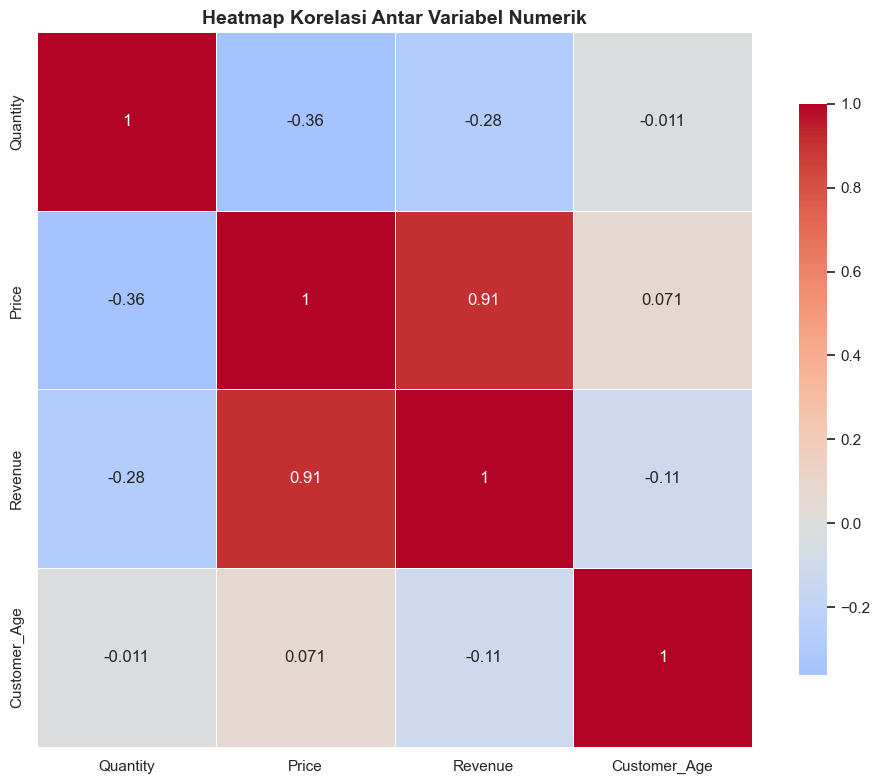

Nilai Korelasi:
              Quantity     Price   Revenue  Customer_Age
Quantity      1.000000 -0.362536 -0.284431     -0.010912
Price        -0.362536  1.000000  0.908016      0.070578
Revenue      -0.284431  0.908016  1.000000     -0.109536
Customer_Age -0.010912  0.070578 -0.109536      1.000000


In [ ]:
# Heatmap korelasi antar variabel numerik
plt.figure(figsize=(10, 8))

# Hitung korelasi
numerical_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numerical_cols].corr()

# Buat heatmap
sns.heatmap(correlation_matrix, 
            annot=True,           # Tampilkan angka
            cmap='coolwarm',      # Color scheme
            center=0,             # Center di 0
            square=True,          # Kotak persegi
            linewidths=0.5,       # Garis pemisah
            cbar_kws={"shrink": 0.8})

plt.title('Heatmap Korelasi Antar Variabel Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📊 Nilai Korelasi:")
print(correlation_matrix)

### 2.2 Heatmap dengan Mask (Triangle)

Kadang kita hanya perlu menampilkan setengah dari matriks korelasi:

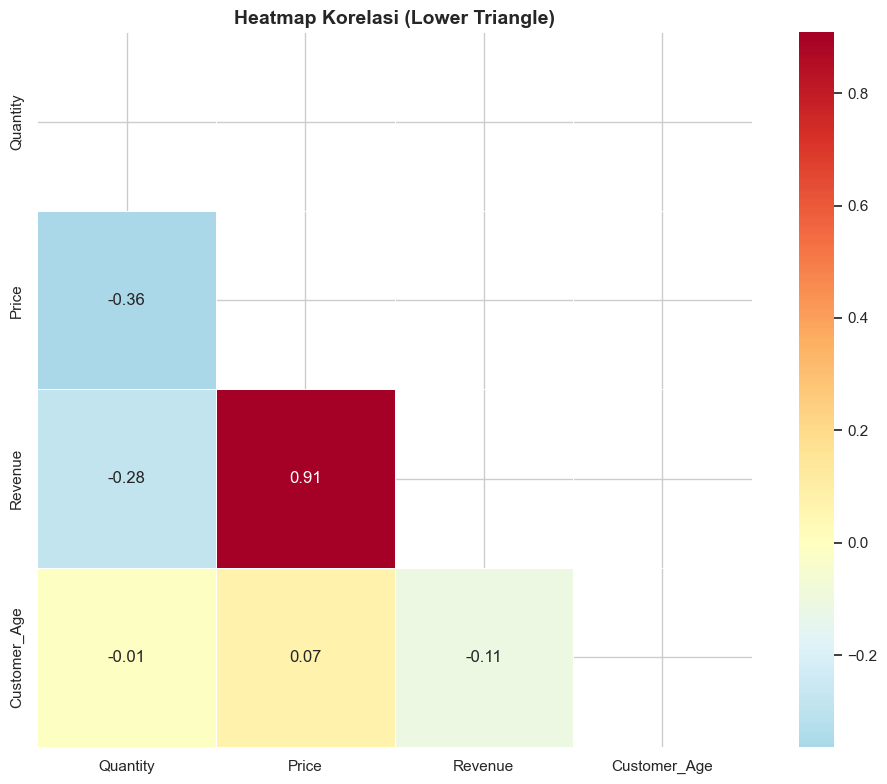

In [5]:
plt.figure(figsize=(10, 8))

# Buat mask untuk upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(correlation_matrix,
            mask=mask,           # Hide upper triangle
            annot=True,
            fmt='.2f',
            cmap='RdYlBu_r',
            center=0,
            square=True,
            linewidths=0.5)

plt.title('Heatmap Korelasi (Lower Triangle)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 3. Pair Plots - Scatter Plot Matrix

**Kapan menggunakan Pair Plot?**
- Melihat hubungan antara semua pasangan variabel
- Eksplorasi data awal
- Mengidentifikasi pola dan outlier

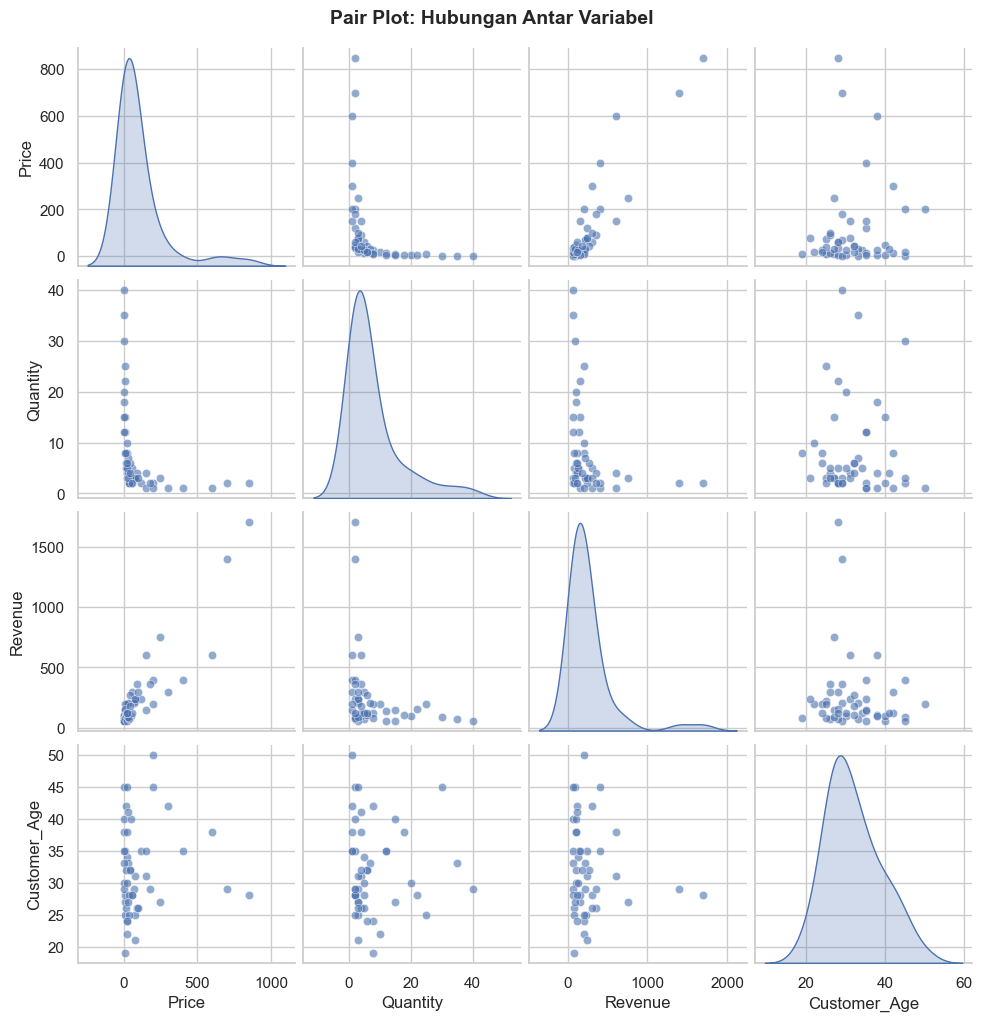

💡 Cara membaca Pair Plot:
- Diagonal: Distribusi setiap variabel
- Off-diagonal: Scatter plot antar 2 variabel


In [6]:
# Pair plot untuk variabel numerik
subset_df = df[['Price', 'Quantity', 'Revenue', 'Customer_Age']]

pairplot = sns.pairplot(subset_df,
                        diag_kind='kde',      # Diagonal: KDE plot
                        plot_kws={'alpha': 0.6})

pairplot.fig.suptitle('Pair Plot: Hubungan Antar Variabel', y=1.02, fontsize=14, fontweight='bold')
plt.show()

print("💡 Cara membaca Pair Plot:")
print("- Diagonal: Distribusi setiap variabel")
print("- Off-diagonal: Scatter plot antar 2 variabel")

### 3.2 Pair Plot dengan Hue (Color Coding)

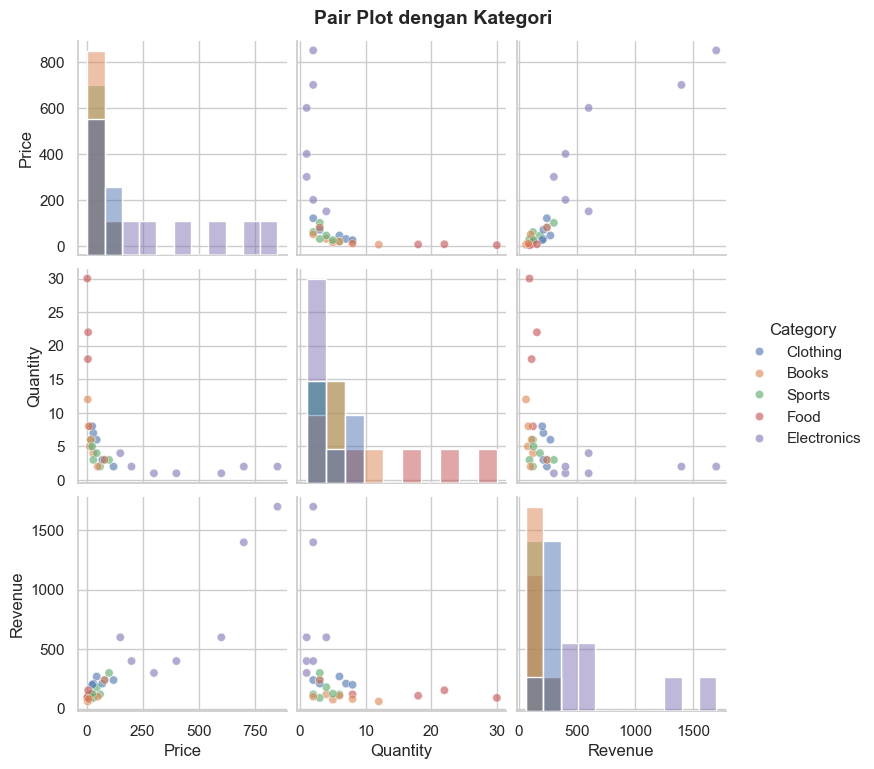

In [7]:
# Pair plot dengan kategori
sample_df = df.sample(30, random_state=42)  # Sample untuk readability

pairplot = sns.pairplot(sample_df[['Price', 'Quantity', 'Revenue', 'Category']],
                        hue='Category',
                        diag_kind='hist',
                        plot_kws={'alpha': 0.6},
                        height=2.5)

pairplot.fig.suptitle('Pair Plot dengan Kategori', y=1.02, fontsize=14, fontweight='bold')
plt.show()

---

## 4. Box Plots - Visualisasi Distribusi dan Outlier

**Kapan menggunakan Box Plot?**
- Melihat distribusi data
- Mengidentifikasi outlier
- Membandingkan distribusi antar grup

/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/359712654.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,


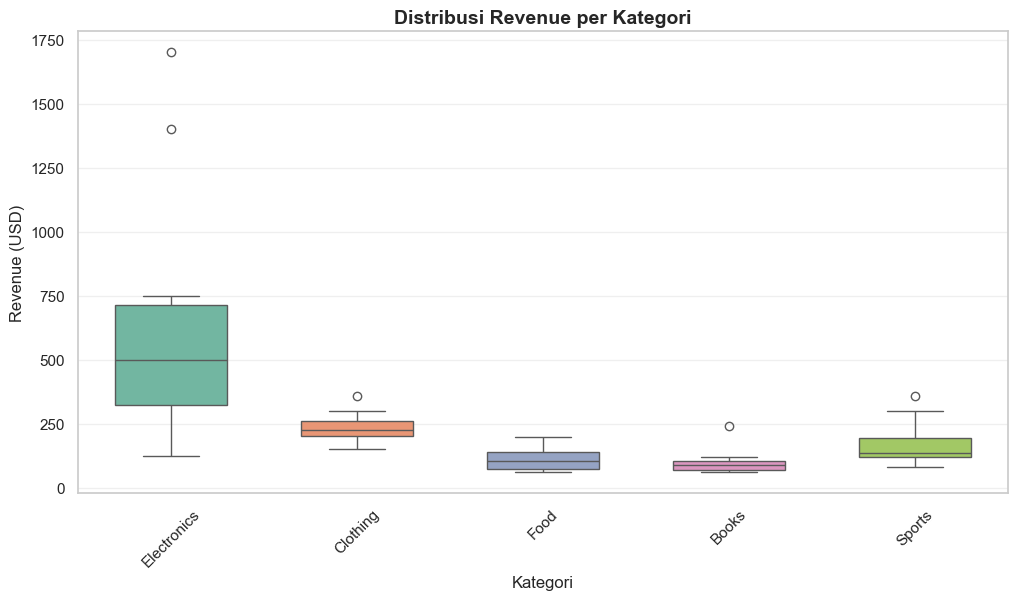

Statistik Revenue per Kategori:
             count   mean         std    min     25%    50%    75%     max
Category                                                                  
Books         10.0  101.3   52.885726   60.0   71.25   90.0  106.0   240.0
Clothing      10.0  238.0   59.591200  150.0  202.50  225.0  262.5   360.0
Electronics   10.0  650.0  514.646589  125.0  325.00  500.0  712.5  1700.0
Food          10.0  110.6   45.206194   60.0   75.00  104.0  138.0   200.0
Sports        10.0  172.5   91.810493   80.0  120.00  137.5  195.0   360.0


In [ ]:
# Box plot: Revenue per kategori
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, 
            x='Category', 
            y='Revenue',
            palette='Set2',
            width=0.6)

plt.title('Distribusi Revenue per Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Kategori', fontsize=12)
plt.ylabel('Revenue (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3, axis='y')

plt.show()

print("\n📦 Statistik Revenue per Kategori:")
print(df.groupby('Category')['Revenue'].describe())

### 4.2 Box Plot dengan Swarm Plot

/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/1097447115.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='Price', palette='pastel')


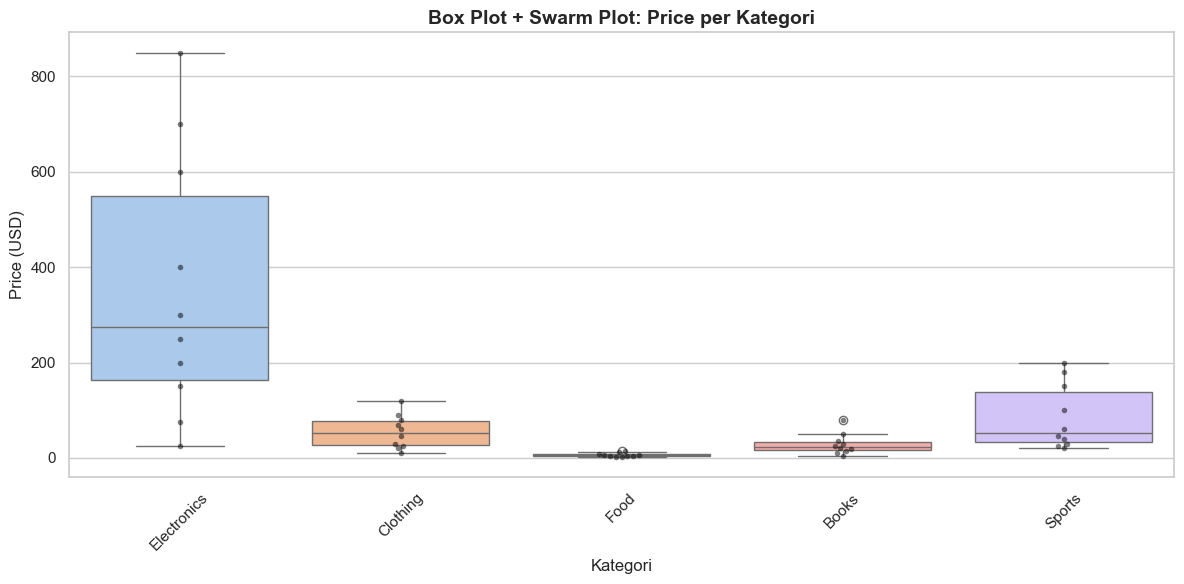

In [10]:
plt.figure(figsize=(12, 6))

# Box plot
sns.boxplot(data=df, x='Category', y='Price', palette='pastel')

# Tambahkan swarm plot untuk melihat titik individual
sns.swarmplot(data=df, x='Category', y='Price', 
              color='black', alpha=0.5, size=4)

plt.title('Box Plot + Swarm Plot: Price per Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Kategori', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 4.3 Violin Plot - Kombinasi Box Plot dan KDE

/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/2564872960.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Category', y='Revenue', ax=axes[0], palette='muted')
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/2564872960.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/2564872960.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Region', y='Customer_Age',


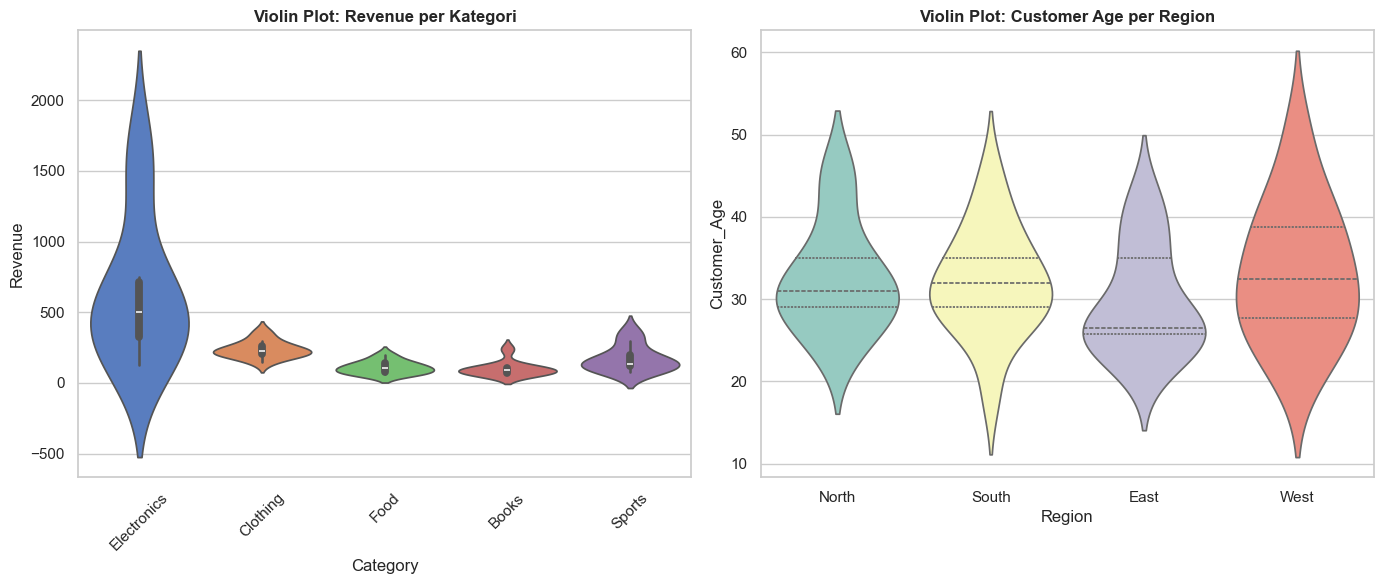

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Violin plot
sns.violinplot(data=df, x='Category', y='Revenue', ax=axes[0], palette='muted')
axes[0].set_title('Violin Plot: Revenue per Kategori', fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Violin plot with inner quartiles
sns.violinplot(data=df, x='Region', y='Customer_Age', 
               ax=axes[1], palette='Set3', inner='quartile')
axes[1].set_title('Violin Plot: Customer Age per Region', fontweight='bold')

plt.tight_layout()
plt.show()

---

## 5. Histogram dan Distribusi Data

**Kapan menggunakan Histogram?**
- Melihat distribusi frekuensi data
- Mengidentifikasi skewness
- Membandingkan distribusi

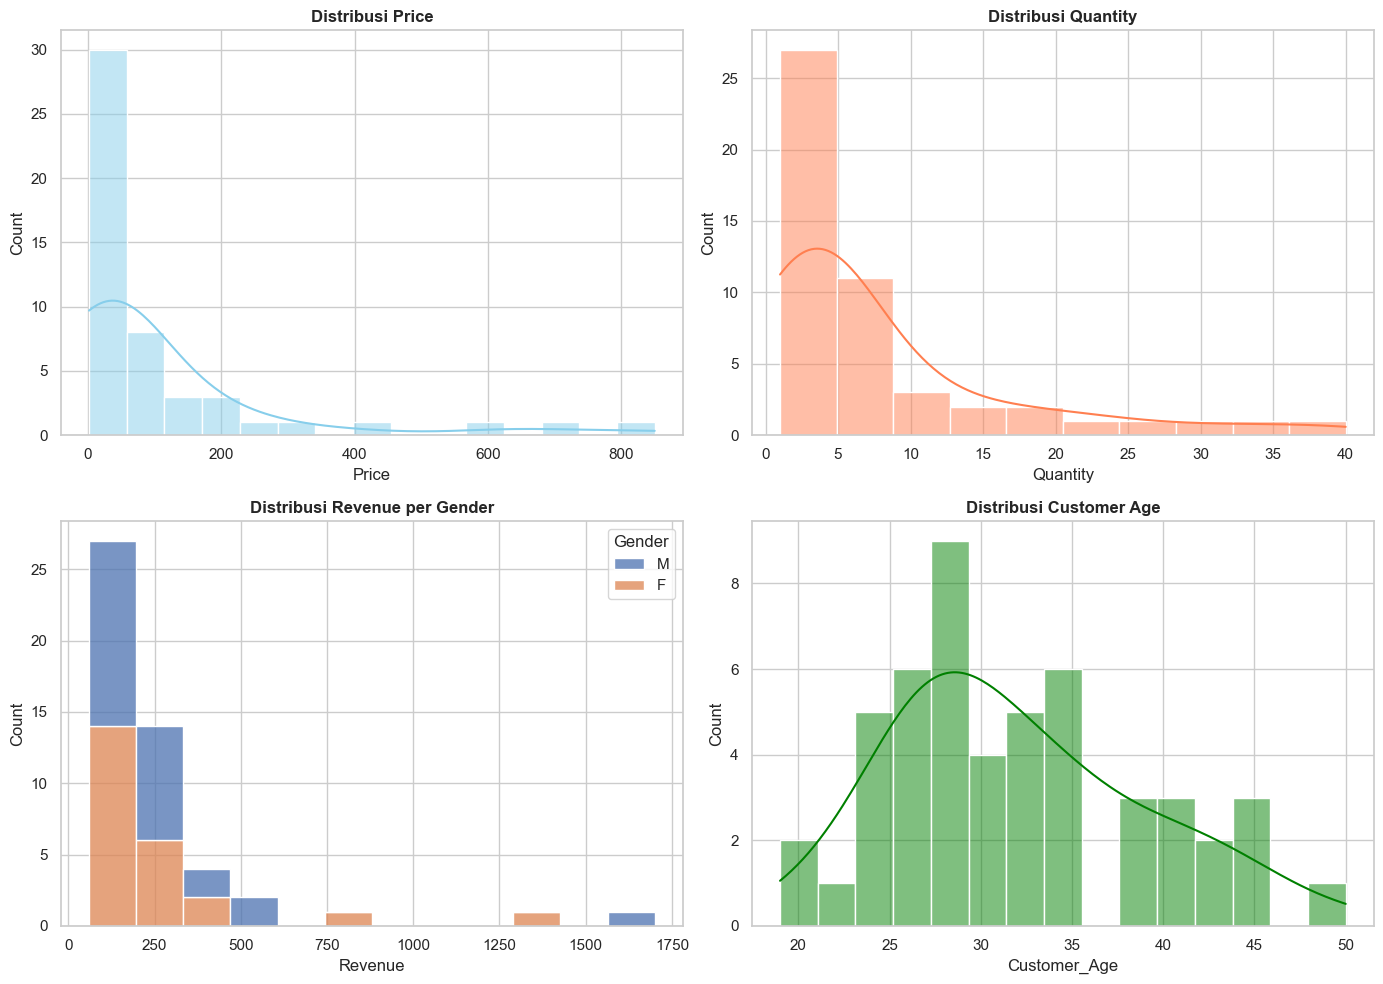

In [12]:
# Histogram dengan KDE
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram 1: Price
sns.histplot(data=df, x='Price', bins=15, kde=True, 
             ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribusi Price', fontweight='bold')

# Histogram 2: Quantity
sns.histplot(data=df, x='Quantity', bins=10, kde=True, 
             ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Distribusi Quantity', fontweight='bold')

# Histogram 3: Revenue with hue
sns.histplot(data=df, x='Revenue', hue='Gender', 
             multiple='stack', bins=12, ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Revenue per Gender', fontweight='bold')

# Histogram 4: Customer Age
sns.histplot(data=df, x='Customer_Age', bins=15, kde=True,
             ax=axes[1, 1], color='green')
axes[1, 1].set_title('Distribusi Customer Age', fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2 KDE Plot (Kernel Density Estimation)

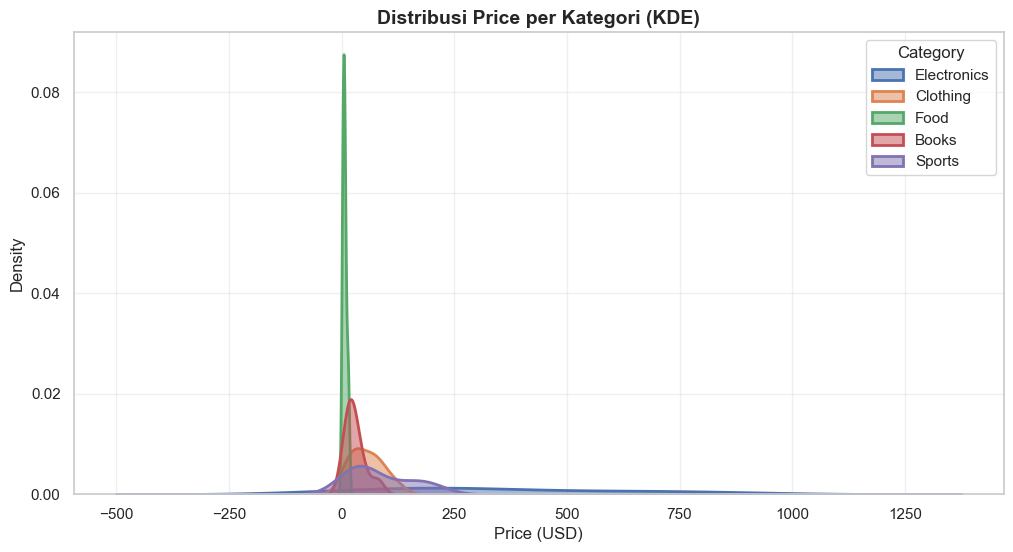

In [13]:
plt.figure(figsize=(12, 6))

# KDE plot untuk beberapa kategori
for category in df['Category'].unique():
    subset = df[df['Category'] == category]
    sns.kdeplot(data=subset, x='Price', label=category, 
                fill=True, alpha=0.5, linewidth=2)

plt.title('Distribusi Price per Kategori (KDE)', fontsize=14, fontweight='bold')
plt.xlabel('Price (USD)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Category')
plt.grid(True, alpha=0.3)

plt.show()

### 5.3 Distribution Plot Comparison

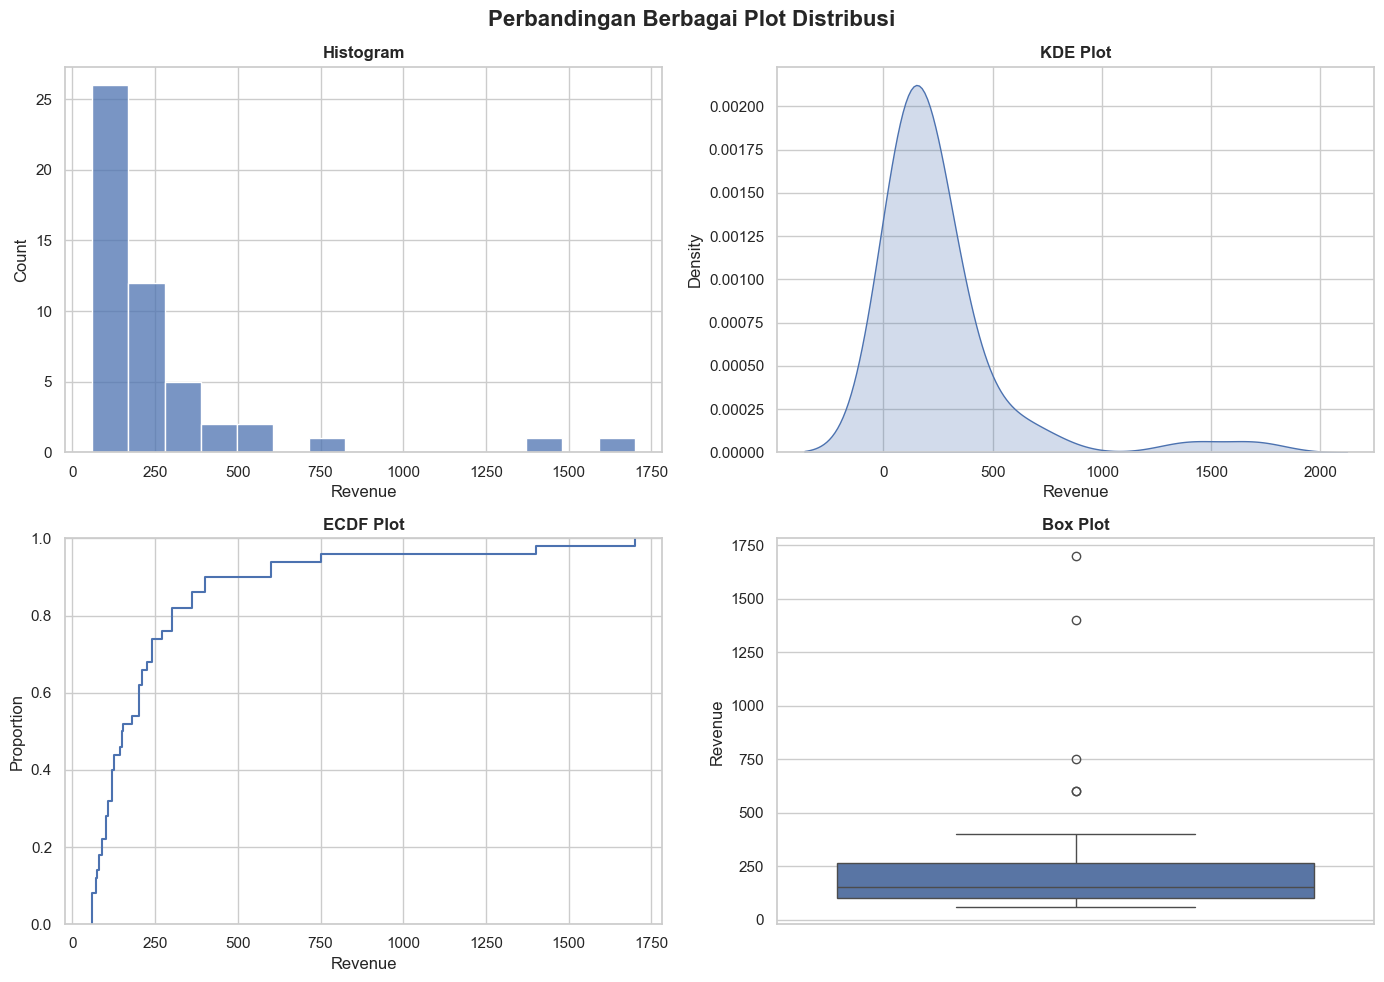

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram
sns.histplot(data=df, x='Revenue', ax=axes[0, 0], bins=15)
axes[0, 0].set_title('Histogram', fontweight='bold')

# KDE Plot
sns.kdeplot(data=df, x='Revenue', ax=axes[0, 1], fill=True)
axes[0, 1].set_title('KDE Plot', fontweight='bold')

# ECDF Plot
sns.ecdfplot(data=df, x='Revenue', ax=axes[1, 0])
axes[1, 0].set_title('ECDF Plot', fontweight='bold')

# Box Plot
sns.boxplot(data=df, y='Revenue', ax=axes[1, 1])
axes[1, 1].set_title('Box Plot', fontweight='bold')

plt.suptitle('Perbandingan Berbagai Plot Distribusi', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 6. Analisis Korelasi

### 6.1 Correlation Analysis

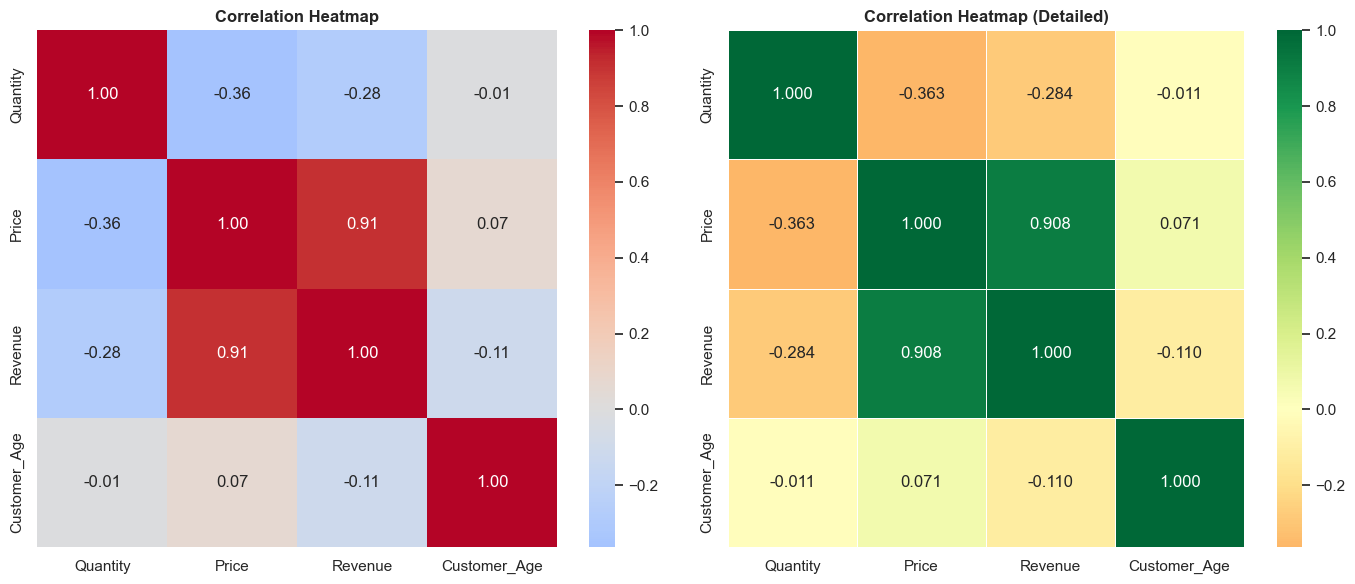


🔝 Top 5 Korelasi Tertinggi:
Price         Revenue         0.908016
Revenue       Price           0.908016
Price         Customer_Age    0.070578
Customer_Age  Price           0.070578
Quantity      Customer_Age   -0.010912
dtype: float64


In [17]:
# Hitung dan visualisasi korelasi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Heatmap korelasi
sns.heatmap(correlation_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Correlation Heatmap', fontweight='bold')

# Heatmap dengan annotation lebih detail
sns.heatmap(correlation_matrix, annot=True, fmt='.3f',
            cmap='RdYlGn', center=0, ax=axes[1], 
            linewidths=0.5, square=True)
axes[1].set_title('Correlation Heatmap (Detailed)', fontweight='bold')

plt.tight_layout()
plt.show()

# Temukan korelasi tertinggi
corr_pairs = correlation_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]  # Exclude self-correlation
print("\n🔝 Top 5 Korelasi Tertinggi:")
print(corr_pairs.head())

### 6.1.2 Clustermap - Hierarchical Clustering

Clustermap mengelompokkan variabel berdasarkan kesamaan pola korelasi:

⚠️ Scipy belum terinstall. Install dengan:
   pip install scipy

Sebagai alternatif, berikut heatmap biasa dengan sorting manual:


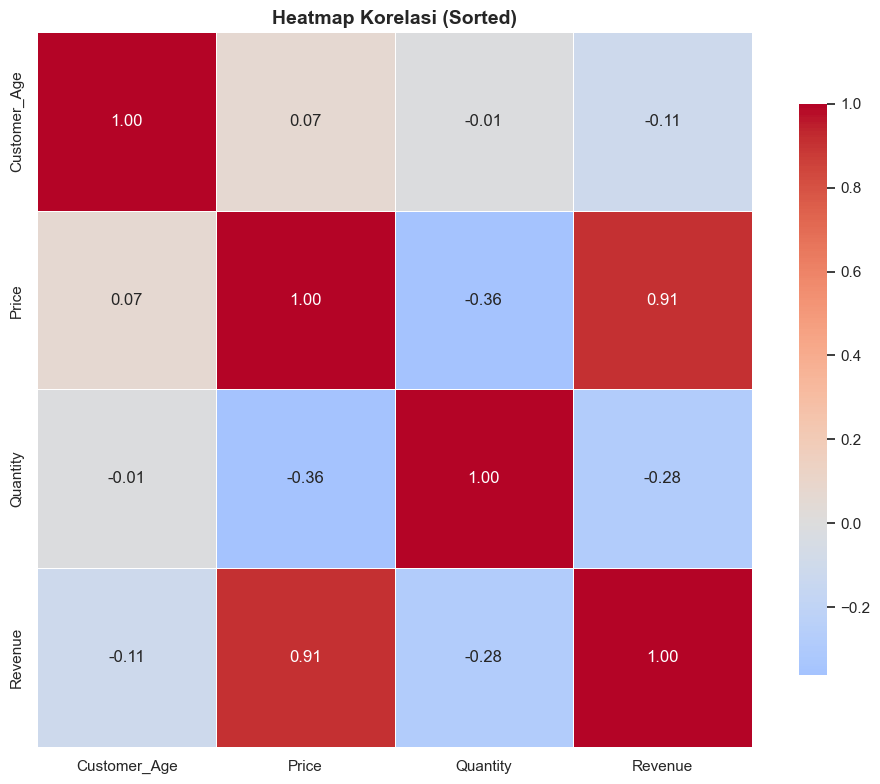

In [19]:
# Clustermap - mengelompokkan variabel dengan korelasi serupa
# Catatan: clustermap memerlukan library scipy
try:
    # Clustermap membuat figure sendiri, tidak bisa di subplot
    clustermap_fig = sns.clustermap(correlation_matrix, 
                                    annot=True, 
                                    fmt='.2f',
                                    cmap='coolwarm', 
                                    center=0, 
                                    figsize=(8, 8),
                                    linewidths=0.5)
    
    clustermap_fig.fig.suptitle('Clustermap: Hierarchical Clustering Korelasi', 
                                fontsize=14, fontweight='bold', y=0.98)
    plt.show()
    
    print("\n💡 Cara membaca Clustermap:")
    print("  - Dendogram (pohon) di kiri/atas menunjukkan grouping variabel")
    print("  - Variabel dengan korelasi mirip dikelompokkan berdekatan")
    print("  - Warna merah = korelasi positif, biru = korelasi negatif")
    
except RuntimeError as e:
    print("⚠️ Scipy belum terinstall. Install dengan:")
    print("   pip install scipy")
    print("\nSebagai alternatif, berikut heatmap biasa dengan sorting manual:")
    
    # Alternative: Heatmap dengan sorted columns
    plt.figure(figsize=(10, 8))
    
    # Sort berdasarkan nilai korelasi
    corr_sorted = correlation_matrix.sort_index(axis=0).sort_index(axis=1)
    
    sns.heatmap(corr_sorted, 
                annot=True, 
                fmt='.2f',
                cmap='coolwarm', 
                center=0, 
                square=True,
                linewidths=0.5,
                cbar_kws={"shrink": 0.8})
    
    plt.title('Heatmap Korelasi (Sorted)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 6.2 Scatter Plots dengan Regression Line

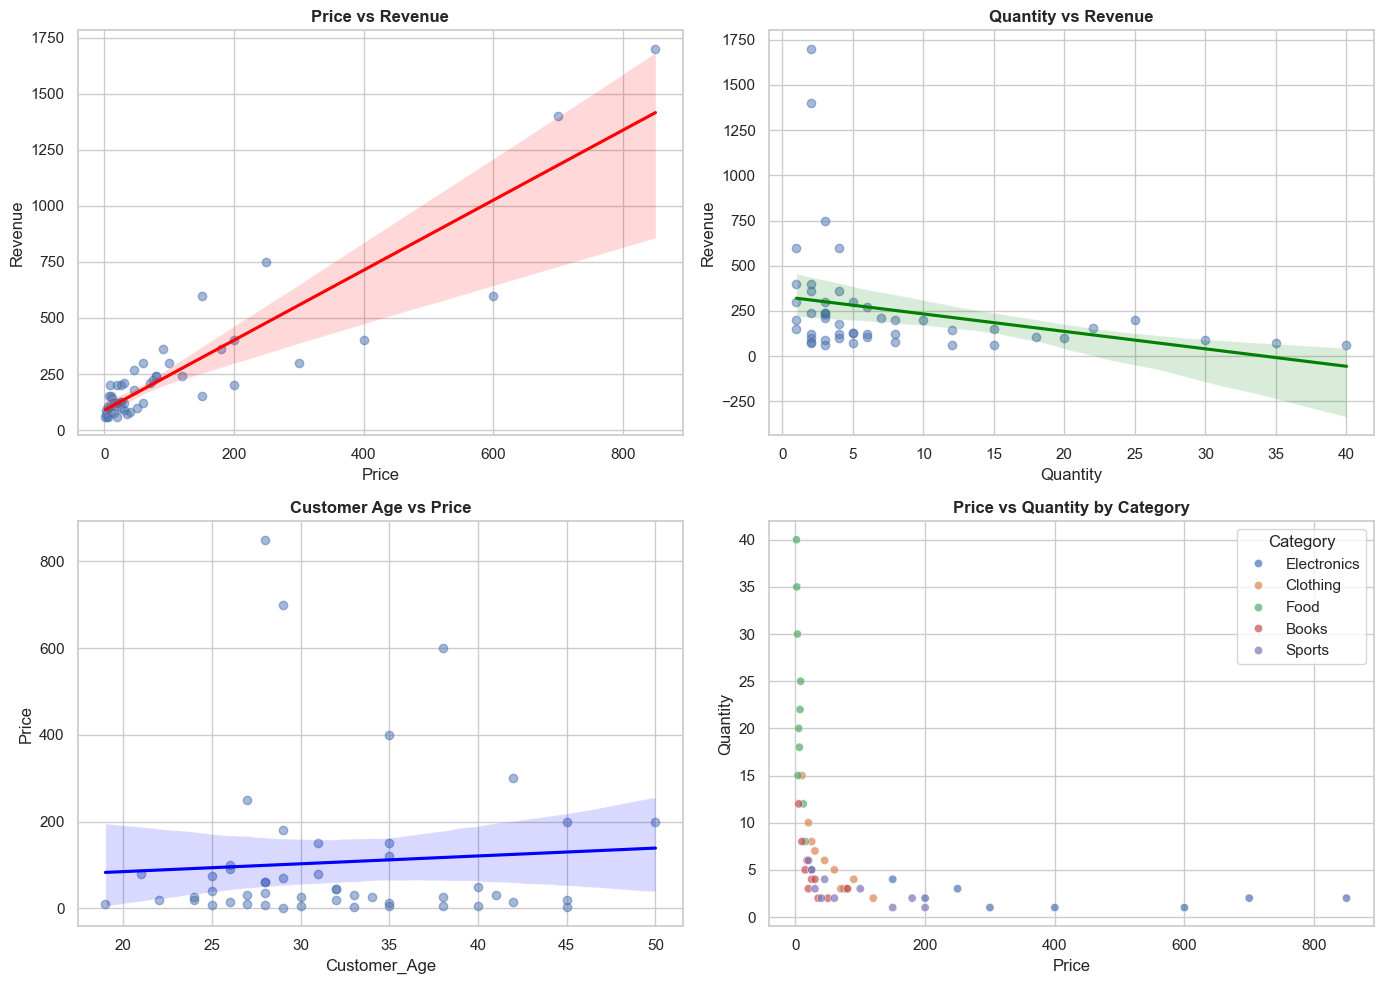

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Regplot 1: Price vs Revenue
sns.regplot(data=df, x='Price', y='Revenue', ax=axes[0, 0],
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
axes[0, 0].set_title('Price vs Revenue', fontweight='bold')

# Regplot 2: Quantity vs Revenue
sns.regplot(data=df, x='Quantity', y='Revenue', ax=axes[0, 1],
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'green'})
axes[0, 1].set_title('Quantity vs Revenue', fontweight='bold')

# Regplot 3: Customer Age vs Price
sns.regplot(data=df, x='Customer_Age', y='Price', ax=axes[1, 0],
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'blue'})
axes[1, 0].set_title('Customer Age vs Price', fontweight='bold')

# Joint plot preview
sns.scatterplot(data=df, x='Price', y='Quantity', hue='Category',
                ax=axes[1, 1], alpha=0.7)
axes[1, 1].set_title('Price vs Quantity by Category', fontweight='bold')

plt.tight_layout()
plt.show()

---

## 7. Advanced Seaborn Features

### 7.1 FacetGrid - Multiple Subplots

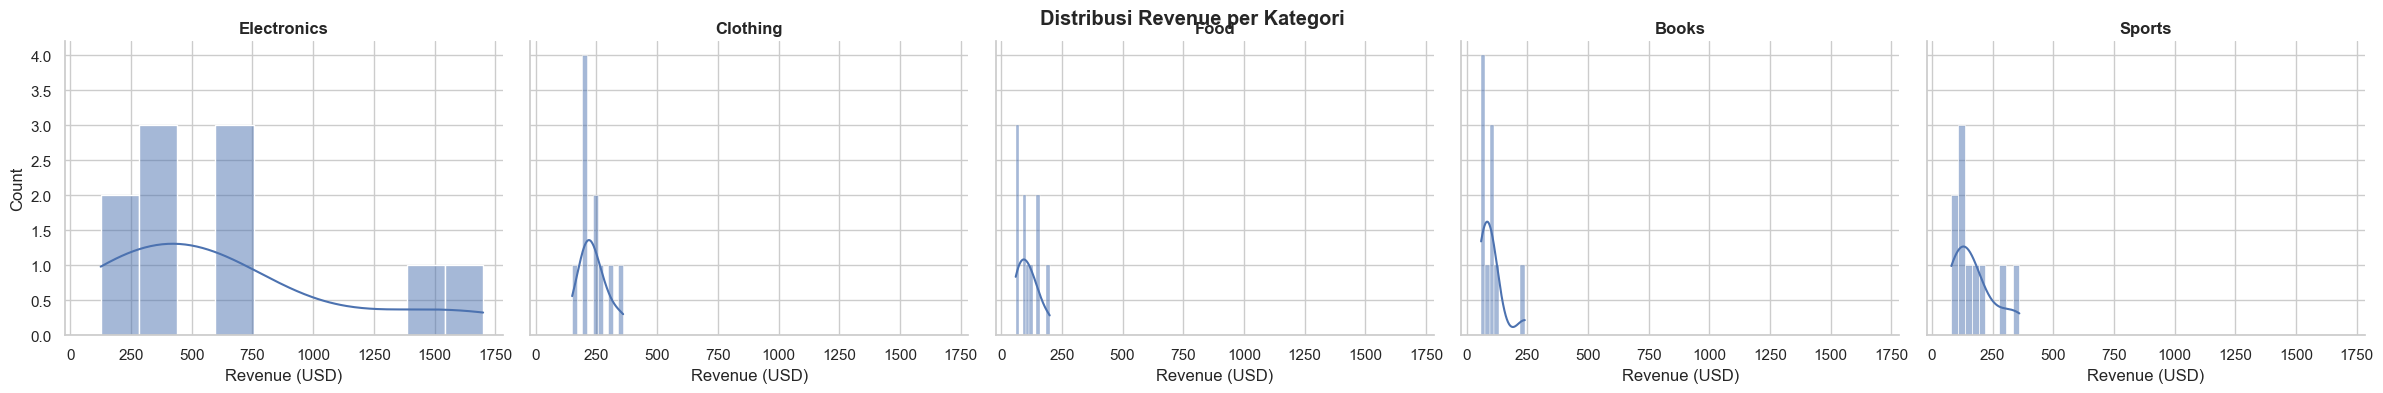

In [21]:
# FacetGrid: Membuat grid of plots
g = sns.FacetGrid(df, col='Category', height=4, aspect=1.2)
g.map(sns.histplot, 'Revenue', bins=10, kde=True)
g.set_titles(col_template="{col_name}", fontweight='bold')
g.set_axis_labels('Revenue (USD)', 'Count')
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribusi Revenue per Kategori', fontweight='bold')
plt.show()

### 7.2 Categorical Plots

/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/1003144886.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Category', ax=axes[0, 0], palette='Set2')
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/1003144886.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Category', y='Revenue', ax=axes[0, 1],
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/1003144886.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Revenue', ax=axes[0, 1],


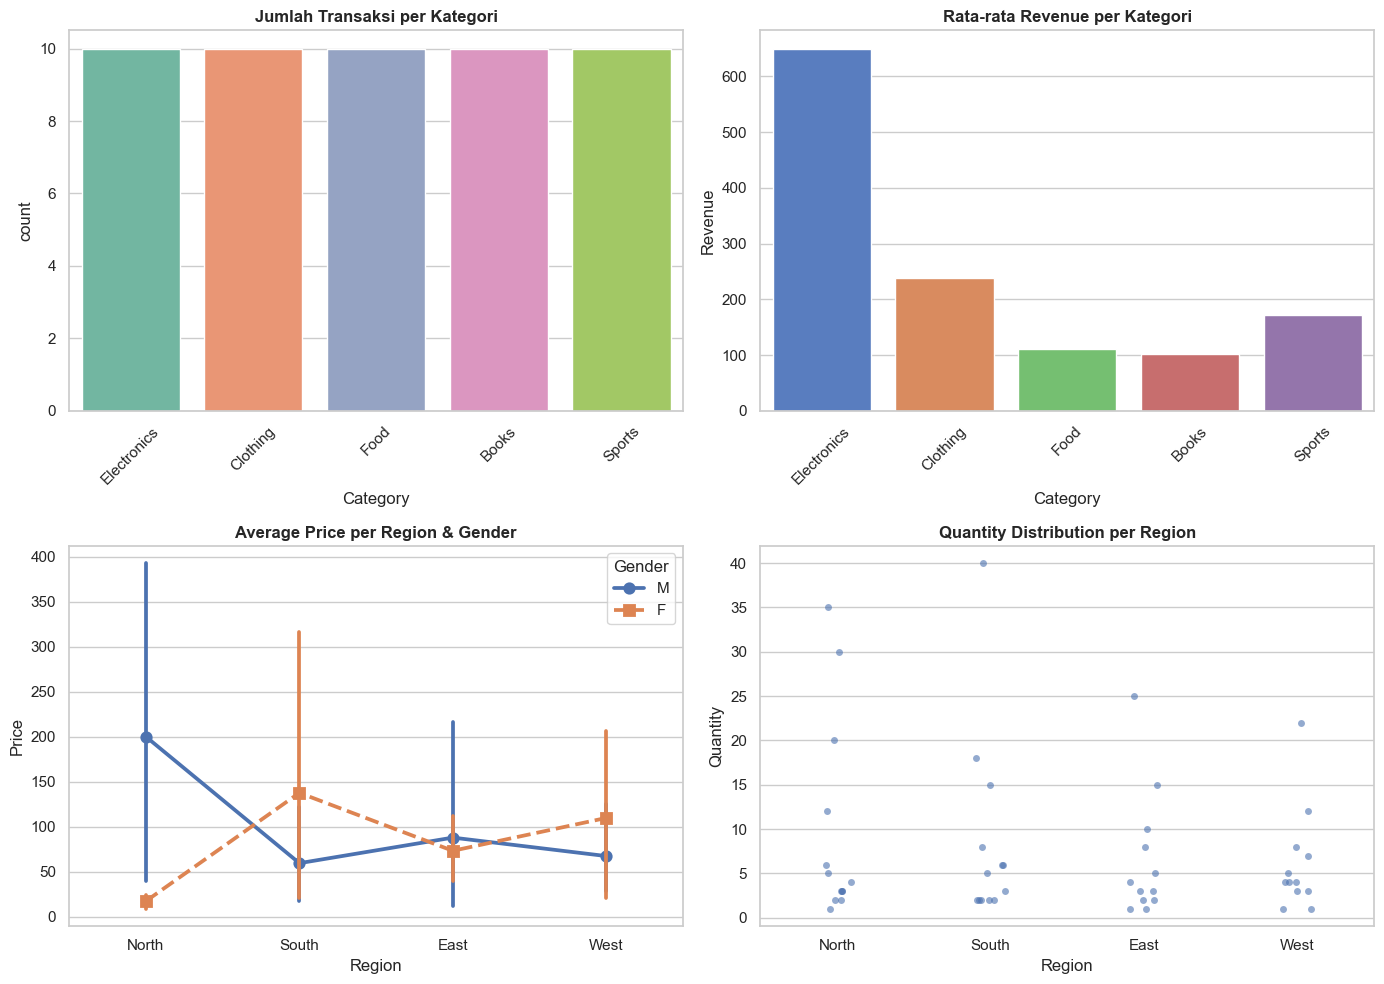

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Count plot
sns.countplot(data=df, x='Category', ax=axes[0, 0], palette='Set2', hue='Category', legend=False)
axes[0, 0].set_title('Jumlah Transaksi per Kategori', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)

# Bar plot (dengan agregasi otomatis)
sns.barplot(data=df, x='Category', y='Revenue', ax=axes[0, 1], 
            palette='muted', hue='Category', legend=False, ci=None)
axes[0, 1].set_title('Rata-rata Revenue per Kategori', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)

# Point plot
sns.pointplot(data=df, x='Region', y='Price', hue='Gender',
              ax=axes[1, 0], markers=['o', 's'], linestyles=['-', '--'])
axes[1, 0].set_title('Average Price per Region & Gender', fontweight='bold')

# Strip plot
sns.stripplot(data=df, x='Region', y='Quantity', ax=axes[1, 1],
              alpha=0.6, jitter=True)
axes[1, 1].set_title('Quantity Distribution per Region', fontweight='bold')

plt.tight_layout()
plt.show()

---

## 8. Seaborn Themes dan Customization

### 8.1 Available Themes

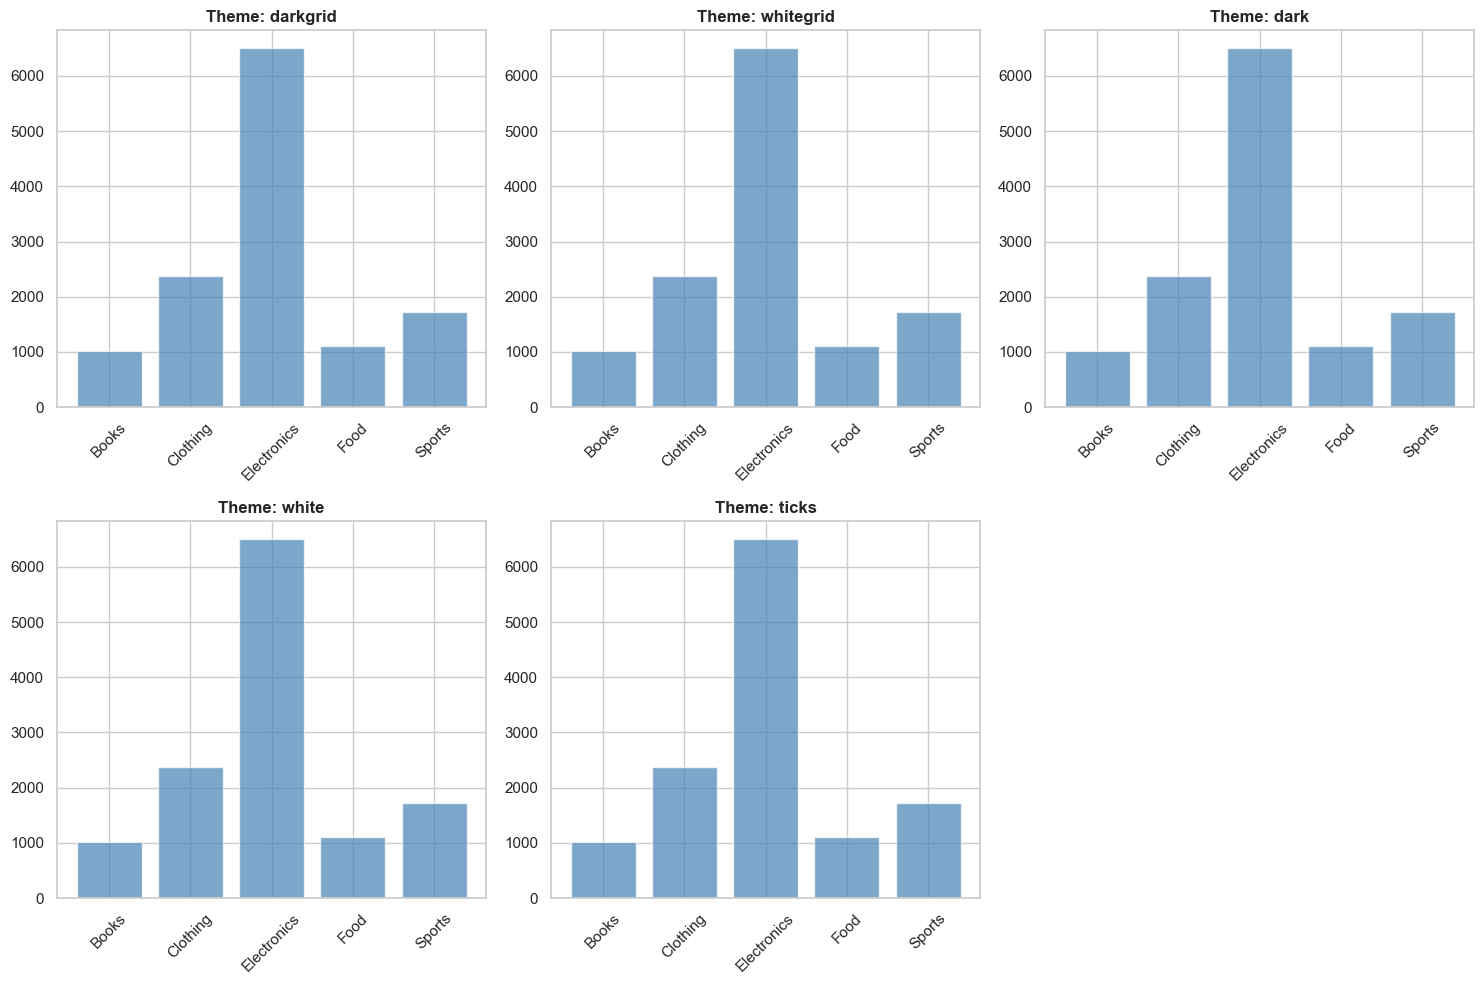


🎨 Available Seaborn Themes:
  - darkgrid
  - whitegrid
  - dark
  - white
  - ticks


In [23]:
# Demonstrasi berbagai theme
themes = ['darkgrid', 'whitegrid', 'dark', 'white', 'ticks']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, theme in enumerate(themes):
    sns.set_theme(style=theme)
    revenue_cat = df.groupby('Category')['Revenue'].sum()
    
    axes[i].bar(revenue_cat.index, revenue_cat.values, color='steelblue', alpha=0.7)
    axes[i].set_title(f'Theme: {theme}', fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)

# Reset ke default
sns.set_theme(style='whitegrid')
axes[-1].axis('off')

plt.tight_layout()
plt.show()

print("\n🎨 Available Seaborn Themes:")
for theme in themes:
    print(f"  - {theme}")

### 8.2 Color Palettes

/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/54286733.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values,
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/54286733.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values,
/var/folders/rz/zrdr7thd0732819nsxh1_40r0000gn/T/ipykernel_98738/54286733.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values,
/var/folders/rz/

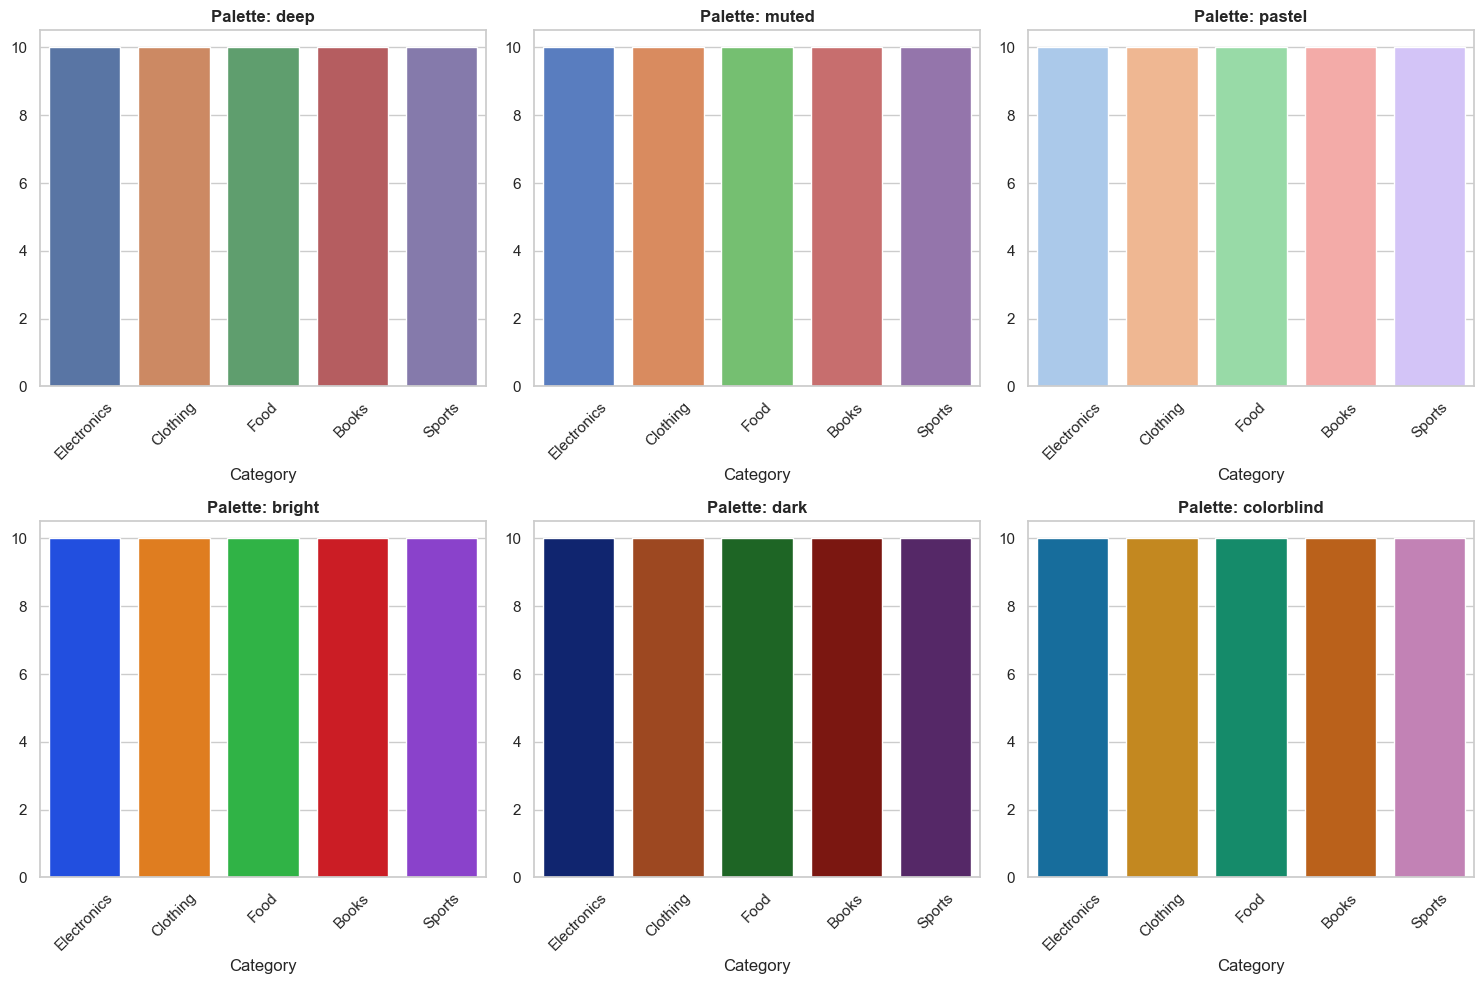


🎨 Tips Memilih Color Palette:
  - 'deep': Warna yang kuat dan jenuh
  - 'muted': Warna yang lebih soft
  - 'pastel': Warna pastel yang lembut
  - 'colorblind': Aman untuk color blind


In [ ]:
# Demonstrasi color palettes
palettes = ['deep', 'muted', 'pastel', 'bright', 'dark', 'colorblind']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

category_counts = df['Category'].value_counts()

for i, palette in enumerate(palettes):
    # Fix: tambahkan hue dan legend=False untuk menghindari FutureWarning
    sns.barplot(x=category_counts.index, y=category_counts.values,
                ax=axes[i], palette=palette, hue=category_counts.index, legend=False)
    axes[i].set_title(f'Palette: {palette}', fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n🎨 Tips Memilih Color Palette:")
print("  - 'deep': Warna yang kuat dan jenuh")
print("  - 'muted': Warna yang lebih soft")
print("  - 'pastel': Warna pastel yang lembut")
print("  - 'colorblind': Aman untuk color blind")

---

## 9. Tips & Best Practices

### 9.1 When to Use Which Plot?

| Tujuan | Plot yang Disarankan |
|--------|---------------------|
| Distribusi 1 variabel | Histogram, KDE, Box Plot |
| Hubungan 2 variabel | Scatter Plot, Regplot |
| Hubungan multiple variabel | Pair Plot, Heatmap |
| Perbandingan kategori | Bar Plot, Box Plot, Violin Plot |
| Trend waktu | Line Plot |
| Komposisi | Pie Chart, Stacked Bar |

### 9.2 Best Practices

✅ **DO:**
- Gunakan Seaborn untuk analisis statistik cepat
- Pilih color palette yang sesuai konteks
- Gunakan hue parameter untuk dimensi tambahan
- Manfaatkan FacetGrid untuk multiple plots
- Selalu beri label yang jelas

❌ **DON'T:**
- Jangan gunakan terlalu banyak warna
- Hindari plot yang terlalu ramai
- Jangan abaikan outlier
- Hindari 3D plot jika tidak perlu

---

## 🎉 Selamat!

Anda telah menyelesaikan Tutorial 2: Visualisasi dengan Seaborn!

**Yang telah Anda pelajari:**
- ✅ Heatmaps untuk visualisasi korelasi
- ✅ Pair plots untuk eksplorasi data
- ✅ Box plots dan violin plots untuk distribusi
- ✅ Histogram dan KDE untuk analisis frekuensi
- ✅ Regression plots untuk melihat trend
- ✅ FacetGrid untuk multiple subplots
- ✅ Customization dengan themes dan palettes

**Selanjutnya:** Lanjut ke `03_exercises.ipynb` untuk menguji pemahaman Anda! 💪

---

## 📚 Referensi Cepat

**Seaborn Plot Types:**
- **Relational:** `scatterplot()`, `lineplot()`, `relplot()`
- **Distributional:** `histplot()`, `kdeplot()`, `ecdfplot()`, `rugplot()`
- **Categorical:** `stripplot()`, `swarmplot()`, `boxplot()`, `violinplot()`, `pointplot()`, `barplot()`, `countplot()`
- **Regression:** `regplot()`, `lmplot()`, `residplot()`
- **Matrix:** `heatmap()`, `clustermap()`
- **Multi-plot:** `FacetGrid()`, `PairGrid()`, `pairplot()`, `jointplot()`

**Themes:** `darkgrid`, `whitegrid`, `dark`, `white`, `ticks`

**Palettes:** `deep`, `muted`, `bright`, `pastel`, `dark`, `colorblind`

**Tips Install Scipy (untuk clustermap):**
```bash
pip install scipy
```

Selamat belajar dan berlatih! 🚀📊